---
title: "Лабораторна робота 7. Оцінювання причинних ефектів методами Causal Machine Learning"
description: "Машинне навчання та методи вилучення знань | PhD F3 «Комп'ютерні науки» | КрНУ ім. М. Остроградського"
author: "&copy; [Valeriy Sydorenko](https://www.linkedin.com/in/valeriy-sydorenko-6782279a/), 2026"
date: today
jupyter: python3
bibliography: mlkdd-references.bib

format:
  html:
    code-fold: show
    code-summary: "Показати код"
    code-overflow: wrap
    toc: true
    toc-depth: 4
    toc-location: right
    number-sections: false
    embed-resources: true
    smooth-scroll: true
---


::: {.callout-note}
## Місце лабораторної роботи в курсі

ЛР6 завершила *Causal Research Specification v0.6*: визначено втручання, результат, цільовий ефект, причинний граф і припущення ідентифікації. ЛР7 переходить від *ідентифікації* до *оцінювання*: порівнюємо методи, досліджуємо гетерогенність і невизначеність, проводимо аудит стійкості причинного твердження.

Підсумковий артефакт -- *Causal Effect Estimation & Validation v0.7*. Це розвиток наскрізного дисертаційного протоколу, а не окреме змагання алгоритмів.
:::

# Мета роботи

Набути практичних навичок оцінювання середнього та умовного середнього причинних ефектів (ATE і CATE) за спостережувальними даними, застосування T-learner, зважування за оберненою ймовірністю (IPW), двічі стійкого оцінювання (AIPW) з cross-fitting, діагностики перекриття та формування обмеженого наукового висновку.

# Завдання роботи

1. Перевірити, чи зберігаються припущення ідентифікації з ЛР6.
2. Створити синтетичний приклад із гетерогенним причинним ефектом.
3. Порівняти наївну різницю середніх із модельними оцінками.
4. Реалізувати T-learner і проаналізувати CATE.
5. Оцінити propensity score та виконати діагностику overlap.
6. Реалізувати IPW і AIPW із позавибірковими nuisance-прогнозами.
7. Оцінити невизначеність і провести аналіз чутливості до обрізання ваг.
8. Перенести процедуру на власну дисертаційну постановку.

# Теоретичні відомості

За консистентності, умовної обмінності $Y(t)\perp T\mid X$ та позитивності $0<P(T=1\mid X=x)<1$ середній причинний ефект ідентифікується через умовні середні:

$$
ATE=\mathbb{E}_X[\mu_1(X)-\mu_0(X)],
\qquad \mu_t(x)=\mathbb{E}[Y\mid T=t,X=x].
$$

*Умовний середній причинний ефект (conditional average treatment effect, CATE)*:

$$
\tau(x)=\mathbb{E}[Y(1)-Y(0)\mid X=x].
$$

*Показник схильності (propensity score)* -- $e(x)=P(T=1\mid X=x)$.

*Доповнене зважування за оберненою ймовірністю (augmented inverse probability weighting, AIPW)*:

$$
\widehat{ATE}_{AIPW}=\frac1n\sum_{i=1}^n\left[
\hat\mu_1(X_i)-\hat\mu_0(X_i)
+\frac{T_i(Y_i-\hat\mu_1(X_i))}{\hat e(X_i)}
-\frac{(1-T_i)(Y_i-\hat\mu_0(X_i))}{1-\hat e(X_i)}
\right].
$$

*Подвійна стійкість (double robustness)* за стандартних умов означає консистентність, коли правильно оцінено хоча б одну з двох компонент -- outcome regression або propensity. Вона **не захищає** від невиміряного змішування, порушення позитивності та помилок причинної постановки [@hernan2020causal; @pearl2009causality].

## Методологічна схема

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Causal Specification<br/>v0.6") --> B("Дані та<br/>цільовий ефект")
 B --> C("T-learner,<br/>IPW, AIPW")
 C --> D("Cross-fitting,<br/>overlap, CI")
 D --> E("Аудит<br/>валідності")
 E --> F("Effect Estimation<br/>v0.7")
```

# Частина I. Навчальний експеримент

## 1. Причинне питання та протокол

**Навчальна ситуація.** Освітня платформа надсилає частині користувачів персоналізовану рекомендацію. Результат $Y$ -- кількісний показник навчальної активності після рекомендації. Передвтручальні ознаки $X_1$ та $X_2$ впливають на призначення рекомендації та на результат. Ефект рекомендації змінюється залежно від $X_1$.

*Причинне питання:* який середній ефект надсилання рекомендації на активність у цільовій популяції та як він змінюється залежно від $X_1$?

- Одиниця аналізу -- користувач.
- $T=1$ -- рекомендацію надіслано; $T=0$ -- не надіслано.
- $Y$ -- активність після моменту призначення.
- Цільові параметри -- ATE та $\tau(x)$.
- $X_1,X_2$ виміряно *до* призначення $T$.
- У генераторі відсутні невиміряні конфаундери та інтерференція; у реальних даних це не можна просто припускати без обґрунтування.

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 X1("X1: попередня<br/>активність") --> T("T: рекомендація")
 X2("X2: контекст") --> T
 X1 --> Y("Y: подальша<br/>активність")
 X2 --> Y
 T --> Y
```

### Завдання 1.1

Сформулюйте різницю між $\mathbb{E}[Y\mid T=1]-\mathbb{E}[Y\mid T=0]$ і ATE. Чому саме $X_1,X_2$ є кандидатами для набору коригування? Чи змінилася б відповідь, якби $X_2$ вимірювалася *після* рекомендації?

## 2. Генерація контрольованих даних

Модель генератора:

$$
e(x)=\sigma(-0.2+0.8x_1-0.4x_2),
\qquad \sigma(z)=\frac{1}{1+e^{-z}}.
$$

$$
Y(0)=1+1.5x_1-0.5x_2+0.5x_1^2+\varepsilon,
$$

$$
Y(1)=Y(0)+\tau(x),\qquad \tau(x)=1+0.8x_1.
$$

Теоретичний $ATE=1$, оскільки $\mathbb{E}[X_1]=0$. Реалізований середній ефект на скінченній вибірці може трохи відрізнятися. Обидва потенційні наслідки зберігаємо *лише для контролю синтетичного експерименту*.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error

SEED = 42
rng = np.random.default_rng(SEED)
n = 2400
X = rng.normal(size=(n, 2))
x1, x2 = X[:, 0], X[:, 1]
sigmoid = lambda z: 1 / (1 + np.exp(-z))

propensity_true = sigmoid(-0.2 + 0.8*x1 - 0.4*x2)
T = rng.binomial(1, propensity_true)
tau_true = 1 + 0.8*x1
noise = rng.normal(size=n)
Y0 = 1 + 1.5*x1 - 0.5*x2 + 0.5*x1**2 + noise
Y1 = Y0 + tau_true
Y = np.where(T == 1, Y1, Y0)

frame = pd.DataFrame({'X1': x1, 'X2': x2, 'T': T, 'Y': Y})
true_ate = float(tau_true.mean())
naive_ate = float(Y[T == 1].mean() - Y[T == 0].mean())
print('Розмір вибірки:', frame.shape)
print('Реалізований справжній ATE:', round(true_ate, 3))
print('Наївна різниця середніх:', round(naive_ate, 3))
display(frame.groupby('T')[['X1', 'X2', 'Y']].mean().round(3))


Розмір вибірки: (2400, 4)
Реалізований справжній ATE: 0.982
Наївна різниця середніх: 2.56


,X1,X2,Y
T,,,
0,-0.348,0.144,0.846
1,0.359,-0.191,3.406


### Завдання 2.1

Поясніть причину відмінності наївної оцінки від справжнього ATE. Які величини в наведеному коді неможливо безпосередньо отримати зі звичайних спостережувальних даних? Запропонуйте мінімальний аудит часової послідовності вимірювань.

## 3. T-learner та гетерогенність ефектів

*T-learner* навчає дві окремі регресійні моделі:

$$
\hat\tau_T(x)=\hat\mu_1(x)-\hat\mu_0(x).
$$

Важливо: близькість прогнозів результату до $Y$ не гарантує точності різниці двох моделей. Тут перевірка CATE можлива завдяки відомому синтетичному генератору; у реальному дослідженні індивідуальні контрфактуали недоступні.


T-learner ATE: 1.079
CATE RMSE (лише синтетична перевірка): 0.492


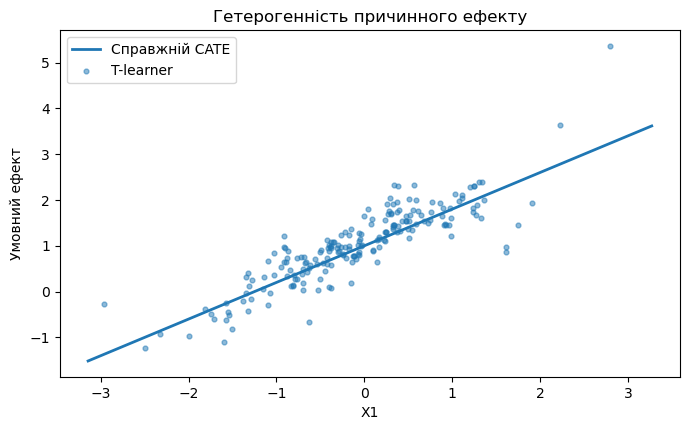

In [2]:
reg0 = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=12, random_state=SEED, n_jobs=1
)
reg1 = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=12, random_state=SEED+1, n_jobs=1
)
reg0.fit(X[T == 0], Y[T == 0])
reg1.fit(X[T == 1], Y[T == 1])
cate_t = reg1.predict(X) - reg0.predict(X)

print('T-learner ATE:', round(float(cate_t.mean()), 3))
print('CATE RMSE (лише синтетична перевірка):',
      round(float(np.sqrt(mean_squared_error(tau_true, cate_t))), 3))

fig, ax = plt.subplots(figsize=(8, 4.5))
order = np.argsort(x1)
ax.plot(x1[order], tau_true[order], linewidth=2, label='Справжній CATE')
ax.scatter(x1[::12], cate_t[::12], s=12, alpha=0.5, label='T-learner')
ax.set(xlabel='X1', ylabel='Умовний ефект', title='Гетерогенність причинного ефекту')
ax.legend()
plt.show()


### Завдання 3.1

Визначте, у яких ділянках $X_1$ оцінка CATE найбільш мінлива. Чи є цей графік доказом гетерогенності в реальному дослідженні? Чому стандартна регресійна метрика не є достатньою для валідації CATE?

## 4. Cross-fitting для nuisance-моделей

Для IPW/AIPW потрібні оцінки $\hat e(x)$, $\hat\mu_0(x)$ та $\hat\mu_1(x)$. Використаємо *cross-fitting*: для кожного спостереження ці прогнози обчислюємо моделями, навченими на інших фолдах. Це зменшує перенавчання в моментних оцінювачах.

Важливо: розбиття KFold є коректним тут завдяки незалежним синтетичним одиницям. За повторними вимірюваннями користувачів, часовою або мережевою залежністю потрібна інша схема розбиття.


In [3]:
kf = KFold(n_splits=3, shuffle=True, random_state=SEED)
e_hat = np.empty(n)
mu0_hat = np.empty(n)
mu1_hat = np.empty(n)
fold_id = np.empty(n, dtype=int)

for fold, (train_idx, holdout_idx) in enumerate(kf.split(X)):
    Xt, Xh = X[train_idx], X[holdout_idx]
    Tt, Yt = T[train_idx], Y[train_idx]
    assert set(train_idx).isdisjoint(set(holdout_idx))

    ps = RandomForestClassifier(
        n_estimators=80, min_samples_leaf=20,
        random_state=SEED+fold, n_jobs=1
    )
    ps.fit(Xt, Tt)
    e_hat[holdout_idx] = ps.predict_proba(Xh)[:, 1]

    for treatment, target in [(0, mu0_hat), (1, mu1_hat)]:
        model = RandomForestRegressor(
            n_estimators=80, min_samples_leaf=15,
            random_state=SEED+fold+treatment+10, n_jobs=1
        )
        model.fit(Xt[Tt == treatment], Yt[Tt == treatment])
        target[holdout_idx] = model.predict(Xh)
    fold_id[holdout_idx] = fold

assert np.isfinite(e_hat).all()
assert np.isfinite(mu0_hat).all() and np.isfinite(mu1_hat).all()
print('Кількість спостережень у фолдах:', np.bincount(fold_id))
print('Propensity: 1%, 50%, 99%:', np.quantile(e_hat, [.01, .5, .99]).round(3))


Кількість спостережень у фолдах: [800 800 800]
Propensity: 1%, 50%, 99%: [0.098 0.464 0.891]


### Завдання 4.1

Поясніть, чому прогноз для кожного спостереження має бути *позавибірковим*. Які витоки інформації можуть виникнути, якщо перед розбиттям виконати відбір ознак, нормалізацію або налаштування гіперпараметрів на всіх даних?

## 5. Діагностика перекриття (overlap)

Перевіримо розподіли propensity за групами та ваги IPW. Числове обрізання propensity застосовуємо лише як явну стабілізаційну процедуру, а не як доказ виконання позитивності.


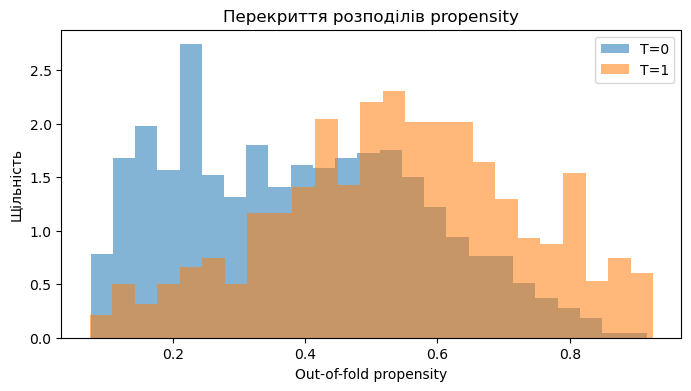

Частка обрізаних значень: 0.0
Квантилі IPW-ваг: [1.73 3.07 7.3 ]
Ефективний розмір вибірки (ESS): 1806.9 із 2400


In [4]:
LOWER, UPPER = 0.05, 0.95
e_safe = np.clip(e_hat, LOWER, UPPER)
weights = T / e_safe + (1-T) / (1-e_safe)
ess = float(weights.sum()**2 / np.sum(weights**2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(e_hat[T == 0], bins=25, density=True, alpha=0.55, label='T=0')
ax.hist(e_hat[T == 1], bins=25, density=True, alpha=0.55, label='T=1')
ax.set(xlabel='Out-of-fold propensity', ylabel='Щільність',
       title='Перекриття розподілів propensity')
ax.legend()
plt.show()
print('Частка обрізаних значень:', round(float(np.mean(e_safe != e_hat)), 3))
print('Квантилі IPW-ваг:', np.quantile(weights, [.5, .9, .99]).round(2))
print('Ефективний розмір вибірки (ESS):', round(ess, 1), 'із', n)


### Завдання 5.1

Поясніть різницю між теоретичною позитивністю та практичним перекриттям. Чому високі ваги зменшують ефективний розмір вибірки? Чи можна за відсутності overlap «врятувати» оцінювання складнішим ML-алгоритмом?

## 6. IPW та AIPW

Реалізуємо два оцінювачі на основі *тих самих* позавибіркових nuisance-прогнозів.

$$
\widehat{ATE}_{IPW}=\frac1n\sum_{i=1}^n\left[
\frac{T_iY_i}{\hat e(X_i)}-\frac{(1-T_i)Y_i}{1-\hat e(X_i)}
\right].
$$

AIPW додає регресійне коригування. Для демонстрації невизначеності використовуємо середнє AIPW-балів та ілюстративний Wald-інтервал за припущення незалежних однаково розподілених одиниць і належної якості nuisance-оцінювання.


In [5]:
ipw_scores = T*Y/e_safe - (1-T)*Y/(1-e_safe)
aipw_scores = (
    mu1_hat-mu0_hat
    + T*(Y-mu1_hat)/e_safe
    - (1-T)*(Y-mu0_hat)/(1-e_safe)
)
ate_ipw = float(ipw_scores.mean())
ate_aipw = float(aipw_scores.mean())
se_aipw = float(aipw_scores.std(ddof=1) / np.sqrt(n))
ci_aipw = (ate_aipw - 1.96*se_aipw, ate_aipw + 1.96*se_aipw)

comparison = pd.DataFrame({
    'Підхід': ['Наївна асоціація', 'T-learner', 'IPW', 'AIPW', 'Справжній ATE (генератор)'],
    'Оцінка': [naive_ate, float(cate_t.mean()), ate_ipw, ate_aipw, true_ate]
})
display(comparison.round(3))
print('Ілюстративний 95% Wald CI для AIPW:',
      tuple(round(v, 3) for v in ci_aipw))


,Підхід,Оцінка
0,Наївна асоціація,2.560
1,T-learner,1.079
2,IPW,1.168
3,AIPW,1.051
4,Справжній ATE (генератор),0.982


Ілюстративний 95% Wald CI для AIPW: (0.941, 1.162)


### Завдання 6.1

Поясніть, чому IPW та AIPW можуть відрізнятися на скінченній вибірці. Що означає *подвійна стійкість* і чого вона не гарантує? Чому наведений довірчий інтервал не враховує невиміряне змішування, часову залежність або невірний DAG?

## 7. Аналіз чутливості до обрізання propensity

Повторимо AIPW для кількох наперед визначених порогів обрізання. Мета -- перевірити, чи змінюється оцінка за допустимих варіантів числової стабілізації. Це **не** є аналізом чутливості до невиміряного змішування.


In [6]:
rows = []
for lower in [0.01, 0.05, 0.10, 0.15]:
    e_adj = np.clip(e_hat, lower, 1-lower)
    score = (mu1_hat-mu0_hat
             +T*(Y-mu1_hat)/e_adj
             -(1-T)*(Y-mu0_hat)/(1-e_adj))
    w = T/e_adj+(1-T)/(1-e_adj)
    rows.append({
        'Поріг': lower,
        'AIPW': float(score.mean()),
        'Частка обрізаних': float(np.mean(e_adj != e_hat)),
        'ESS': float(w.sum()**2/np.sum(w**2))
    })
sensitivity = pd.DataFrame(rows)
display(sensitivity.round(3))


,Поріг,AIPW,Частка обрізаних,ESS
0,0.01,1.051,0.000,1806.860
1,0.05,1.051,0.000,1806.860
2,0.10,1.052,0.017,1836.510
3,0.15,1.062,0.089,1920.801


### Завдання 7.1

Проаналізуйте стійкість оцінки до порогів. Чи змінює обрізання цільовий параметр або вводить додаткове зміщення? Чому стабільність за порогами ще не доводить причинної валідності?

## 8. Перевірка гетерогенності за попередньо визначеними підгрупами

Візьмемо підгрупи $X_1<0$ і $X_1\ge 0$. Порівняємо середні оцінки T-learner з відомими ефектами генератора. Для реальних даних істинні значення невідомі; додатково потрібна незалежна валідація підгрупових ефектів.


In [7]:
subgroups = np.where(x1 < 0, 'X1 < 0', 'X1 >= 0')
subgroup_table = pd.DataFrame({
    'Підгрупа': subgroups,
    'T-learner CATE': cate_t,
    'Істинний CATE (тільки симуляція)': tau_true
}).groupby('Підгрупа').mean()
display(subgroup_table.round(3))


,T-learner CATE,Істинний CATE (тільки симуляція)
Підгрупа,,
X1 < 0,0.392,0.359
X1 >= 0,1.781,1.620


### Завдання 8.1

Чому групи потрібно визначити *до* перегляду результатів? Які ризики множинного пошуку підгруп? Чи можна інтерпретувати різницю оцінених CATE як доказ гетерогенності без оцінювання невизначеності?

## 9. Аудит достовірності причинного оцінювання

Заповніть матрицю за результатами виконання.

| Компонент | Перевірка | Залишкове обмеження |
|---|---|---|
| Причинна постановка | DAG, часовий порядок, estimand | Невиміряні причини |
| Позитивність | Overlap, ваги, ESS | Екстраполяція за межі підтримки |
| Nuisance-моделі | Cross-fitting, стійкість до параметрів | Модельна похибка |
| ATE | IPW/AIPW, CI, чутливість до обрізання | Залежність від припущень |
| CATE | Заздалегідь визначені підгрупи | Post-selection bias, невизначеність |
| Відтворюваність | Seed, версії бібліотек, код | Зсув домену та нові дані |

### Завдання 9.1

Сформулюйте одне *підтримане* та одне *непідтримане* наукове твердження. Чітко розділіть контрольовану симуляцію та можливі висновки на реальних спостережувальних даних.

# Частина II. Перенесення на дисертаційне дослідження

## 10. Актуалізація Causal Research Specification v0.6

Перевірте сформульовані в ЛР6: втручання, результат, одиницю аналізу, часовий порядок, DAG, набір коригування та припущення. Якщо причинний ефект неідентифікований за наявних даних, зафіксуйте це як результат методологічного аудиту; **не замінюйте** ідентифікацію складним алгоритмом.

## 11. Вибір estimand та оцінювача

Для власної задачі обґрунтуйте вибір ATE, ATT або CATE. Складіть таблицю альтернатив: IPW, AIPW, T-learner, DML чи causal forest -- із зазначенням причин застосовності та обмежень. Не обов'язково реалізовувати всі методи: мета -- *методологічно обґрунтований вибір*.

## 12. План nuisance-оцінювання

Зафіксуйте змінні $X$, модель propensity, моделі результату, схему cross-fitting та допустимі налаштування. Для залежних даних передбачте групове, часове або інше змістовно коректне розбиття. Обґрунтуйте, які ознаки є передвтручальними.

## 13. План діагностики та невизначеності

Передбачте аналіз overlap, екстремальних ваг, ESS, оцінювання невизначеності з урахуванням структури даних, чутливість до nuisance-специфікацій і можливого невиміряного змішування. Не трактуйте *числову стійкість* як доказ *причинної ідентифікації*.

## 14. Підсумковий артефакт -- Causal Effect Estimation & Validation v0.7

Подайте компактний протокол:

1. Причинне питання та цільова популяція.
2. Втручання, результат і estimand.
3. DAG та обґрунтований набір коригування.
4. Ідентифікаційні припущення і можливі порушення.
5. Обраний оцінювач та альтернативний baseline.
6. Nuisance-моделі та схема cross-fitting.
7. Overlap, ваги й план оцінювання невизначеності.
8. Аналіз чутливості та обмеження.
9. Результати мінімального експерименту (якщо дані придатні).
10. Одне обмежене наукове твердження та перелік того, чого дані не доводять.

# Контрольні питання

1. Чим відрізняються ATE, ATT та CATE?
2. Чому CATE не дорівнює індивідуальному причинному ефекту?
3. Що означає propensity score?
4. Які припущення потрібні для ідентифікації ATE?
5. Чому звичайна різниця середніх може бути зміщеною?
6. Як працює T-learner?
7. Чому оцінки T-learner потребують окремого аудиту?
8. Що таке IPW і чому екстремальні ваги небезпечні?
9. Що означає double robustness?
10. Навіщо потрібен cross-fitting?
11. Що показує ESS?
12. Чому обрізання propensity не виправляє відсутність overlap?
13. Чому на реальних даних не можна напряму виміряти RMSE індивідуальних ефектів?
14. Які ризики post-hoc пошуку підгруп?
15. Як відрізнити стійкість оцінювача від достовірності причинного висновку?

# Вимоги до звіту

Звіт містить: постановку причинного питання; DAG; таблицю результатів наївного, T-learner, IPW та AIPW-оцінювання; діагностику overlap й ESS; аналіз чутливості; обґрунтовані висновки щодо CATE; матрицю загроз валідності; артефакт *Causal Effect Estimation & Validation v0.7* для власної теми. Результати симуляції не слід подавати як емпіричні свідчення щодо реальної освітньої платформи.

# Висновки

Причинне машинне навчання дозволяє оцінювати середні та гетерогенні ефекти за складних залежностей, але достовірність результату визначається не складністю моделі, а причинною постановкою, припущеннями ідентифікації, overlap, організацією оцінювання та прозорим аудитом невизначеності.

# Література та ресурси

Основні джерела: [@hernan2020causal; @pearl2009causality; @peters2017elements; @hastie2009elements].

Додатково: [EconML](https://www.pywhy.org/EconML/), [DoubleML](https://docs.doubleml.org/), [scikit-learn](https://scikit-learn.org/stable/).

::: {#refs}
:::
